In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

print("Libraries imported successfully!")
print("OpenCV Version:", cv2.__version__)

Libraries imported successfully!
OpenCV Version: 4.10.0


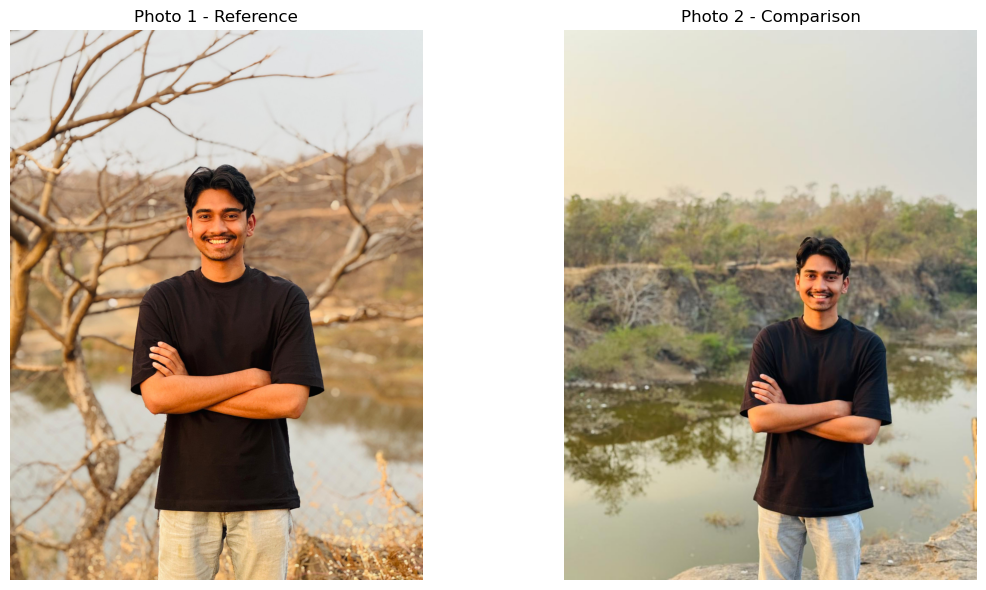

Image 1 dimensions: (4032, 3024, 3)
Image 2 dimensions: (1280, 960, 3)


In [3]:
# Set project and dataset paths
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "dataset"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task2_features"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load both images
image1_path = DATASET_DIR / "feature_photo_1.jpg"
image2_path = DATASET_DIR / "feature_photo_2.jpg"

image1 = cv2.imread(str(image1_path))
image2 = cv2.imread(str(image2_path))

# Check whether images loaded successfully
if image1 is None or image2 is None:
    raise FileNotFoundError("Check whether both photos exist in the dataset folder.")

# Convert BGR to RGB
image1_rgb = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
image2_rgb = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

# Display images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image1_rgb)
plt.title("Photo 1 - Reference")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image2_rgb)
plt.title("Photo 2 - Comparison")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image 1 dimensions:", image1.shape)
print("Image 2 dimensions:", image2.shape)

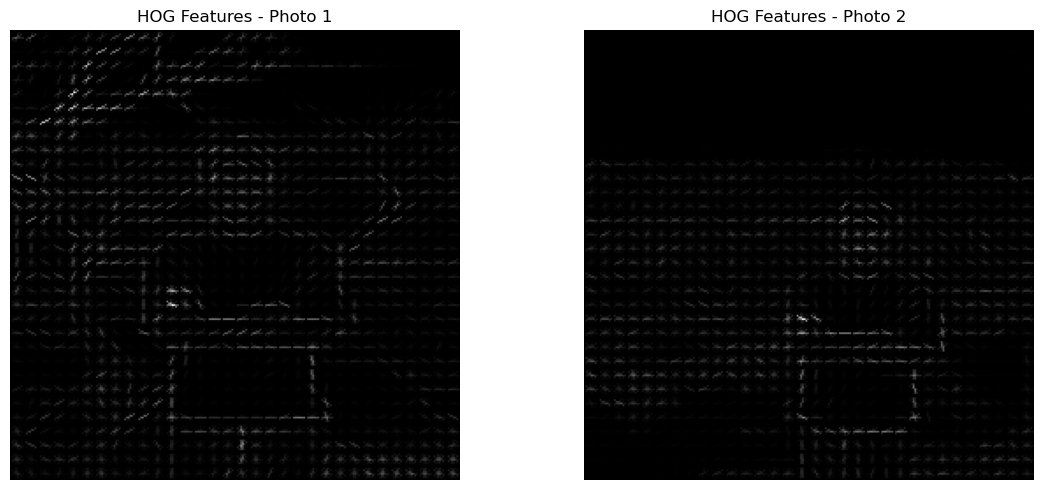

Photo 1 HOG feature length: 34596
Photo 2 HOG feature length: 34596


In [5]:
from skimage.feature import hog

# Convert images to grayscale
gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

# Resize images to the same dimensions
gray1_resized = cv2.resize(gray1, (256, 256))
gray2_resized = cv2.resize(gray2, (256, 256))

# Extract HOG features
hog_features1, hog_image1 = hog(
    gray1_resized,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

hog_features2, hog_image2 = hog(
    gray2_resized,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

# Display HOG visualizations
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(hog_image1, cmap="gray")
plt.title("HOG Features - Photo 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image2, cmap="gray")
plt.title("HOG Features - Photo 2")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Photo 1 HOG feature length:", len(hog_features1))
print("Photo 2 HOG feature length:", len(hog_features2))

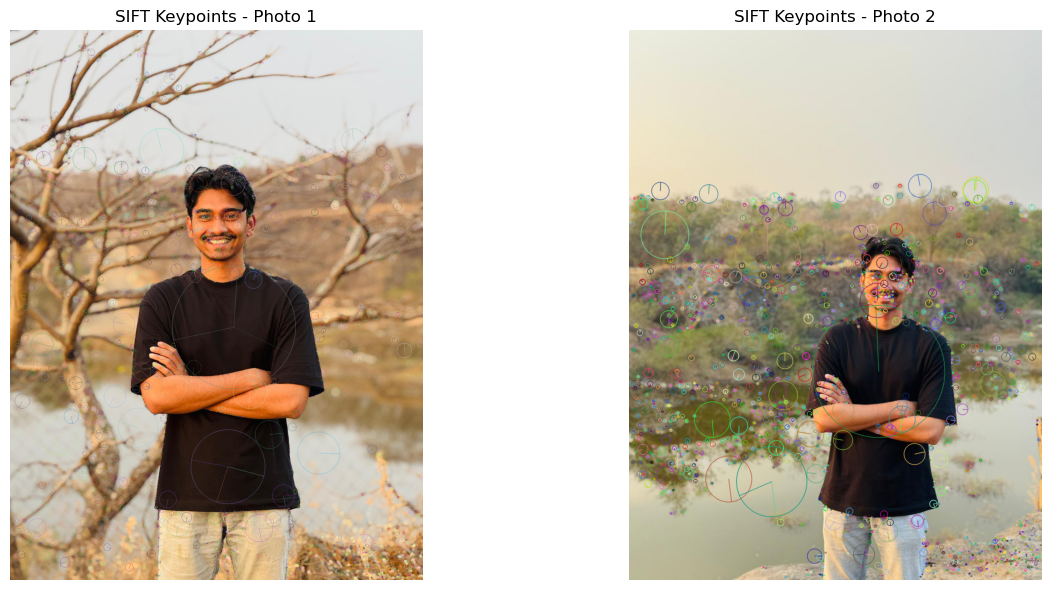

Photo 1 keypoints: 3740
Photo 2 keypoints: 1513
Photo 1 descriptor shape: (3740, 128)
Photo 2 descriptor shape: (1513, 128)


In [7]:
# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and calculate descriptors
keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

# Draw keypoints on images
sift_image1 = cv2.drawKeypoints(
    image1_rgb, keypoints1, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

sift_image2 = cv2.drawKeypoints(
    image2_rgb, keypoints2, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(sift_image1)
plt.title("SIFT Keypoints - Photo 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sift_image2)
plt.title("SIFT Keypoints - Photo 2")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Photo 1 keypoints:", len(keypoints1))
print("Photo 2 keypoints:", len(keypoints2))
print("Photo 1 descriptor shape:", descriptors1.shape if descriptors1 is not None else None)
print("Photo 2 descriptor shape:", descriptors2.shape if descriptors2 is not None else None)

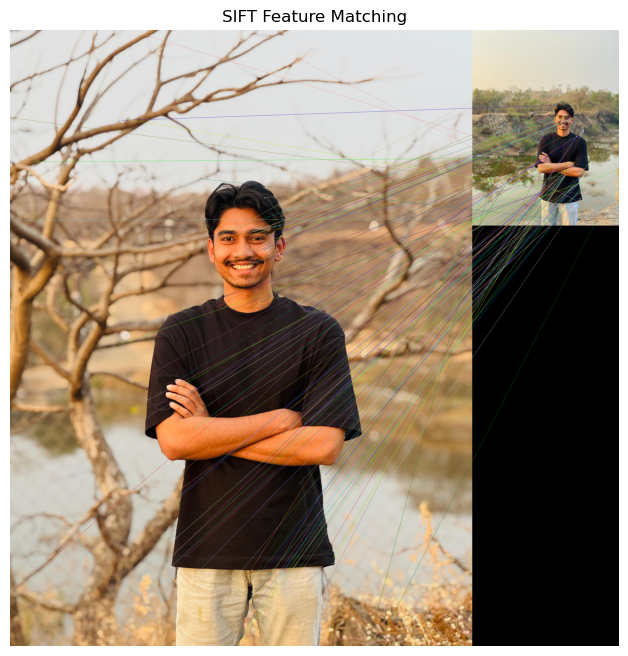

Total matches: 3740
Good matches: 117


In [9]:
# Check whether descriptors are available
if descriptors1 is None or descriptors2 is None:
    raise ValueError("SIFT could not detect enough features in one of the images.")

# Create Brute-Force Matcher
bf = cv2.BFMatcher(cv2.NORM_L2)

# Find the two nearest matches
matches = bf.knnMatch(descriptors1, descriptors2, k=2)

# Apply Lowe's ratio test
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

# Draw good matches
matched_image = cv2.drawMatches(
    image1_rgb,
    keypoints1,
    image2_rgb,
    keypoints2,
    good_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display matching result
plt.figure(figsize=(16, 8))
plt.imshow(matched_image)
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

print("Total matches:", len(matches))
print("Good matches:", len(good_matches))

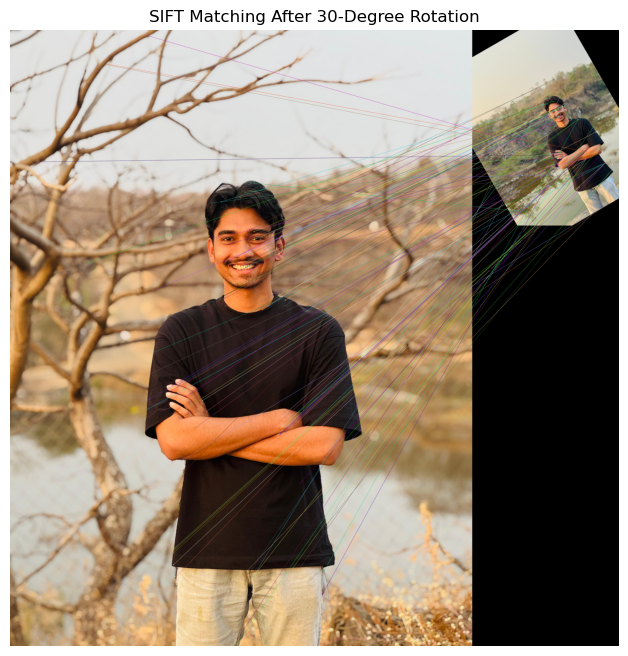

Good matches after rotation: 105


In [11]:
# Rotate Photo 2 by 30 degrees
height, width = gray2.shape

rotation_matrix = cv2.getRotationMatrix2D(
    (width // 2, height // 2), 30, 1.0
)

rotated_image = cv2.warpAffine(
    image2, rotation_matrix, (width, height)
)

rotated_gray = cv2.cvtColor(rotated_image, cv2.COLOR_BGR2GRAY)

# Detect SIFT features in rotated image
rotated_keypoints, rotated_descriptors = sift.detectAndCompute(
    rotated_gray, None
)

# Match descriptors
rotated_matches = bf.knnMatch(
    descriptors1, rotated_descriptors, k=2
)

# Apply Lowe's ratio test
good_rotated_matches = []

for pair in rotated_matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_rotated_matches.append(m)

# Draw matches
rotated_match_image = cv2.drawMatches(
    image1_rgb,
    keypoints1,
    cv2.cvtColor(rotated_image, cv2.COLOR_BGR2RGB),
    rotated_keypoints,
    good_rotated_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display result
plt.figure(figsize=(16, 8))
plt.imshow(rotated_match_image)
plt.title("SIFT Matching After 30-Degree Rotation")
plt.axis("off")
plt.show()

print("Good matches after rotation:", len(good_rotated_matches))

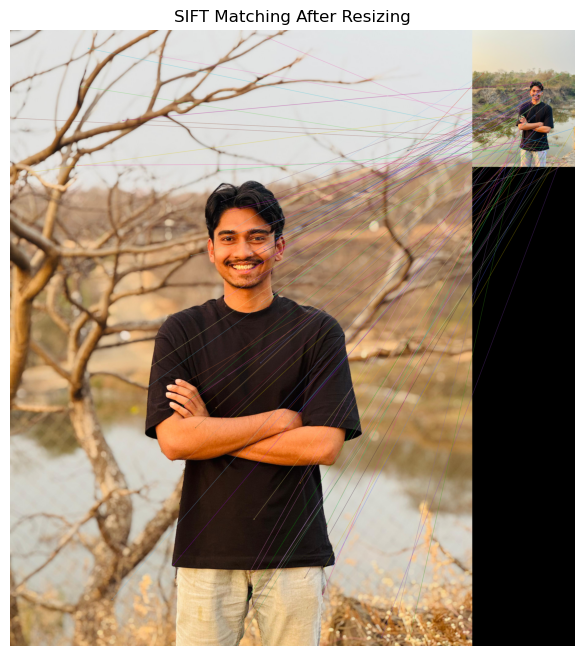

Good matches after resizing: 90


In [13]:
# Resize Photo 2 to 70%
resized_image = cv2.resize(
    image2,
    None,
    fx=0.7,
    fy=0.7,
    interpolation=cv2.INTER_LINEAR
)

resized_gray = cv2.cvtColor(
    resized_image, cv2.COLOR_BGR2GRAY
)

# Detect SIFT features
resized_keypoints, resized_descriptors = sift.detectAndCompute(
    resized_gray, None
)

if resized_descriptors is None:
    raise ValueError("No SIFT features detected in resized image.")

# Match descriptors
resized_matches = bf.knnMatch(
    descriptors1, resized_descriptors, k=2
)

# Apply Lowe's ratio test
good_resized_matches = []

for pair in resized_matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good_resized_matches.append(m)

# Draw matches
resized_match_image = cv2.drawMatches(
    image1_rgb,
    keypoints1,
    cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB),
    resized_keypoints,
    good_resized_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display result
plt.figure(figsize=(16, 8))
plt.imshow(resized_match_image)
plt.title("SIFT Matching After Resizing")
plt.axis("off")
plt.show()

print("Good matches after resizing:", len(good_resized_matches))

In [15]:
# Create comparison table
comparison_data = {
    "Experiment": [
        "Original Images",
        "After 30-Degree Rotation",
        "After 70% Resizing"
    ],
    "Good Matches": [
        len(good_matches),
        len(good_rotated_matches),
        len(good_resized_matches)
    ]
}

matching_comparison = pd.DataFrame(comparison_data)

display(matching_comparison)

# Save comparison table
matching_comparison.to_csv(
    OUTPUT_DIR / "feature_matching_comparison.csv",
    index=False
)

,Experiment,Good Matches
0,Original Images,117
1,After 30-Degree Rotation,105
2,After 70% Resizing,90


In [17]:
# Save HOG visualizations
plt.imsave(
    OUTPUT_DIR / "hog_photo1.png",
    hog_image1,
    cmap="gray"
)

plt.imsave(
    OUTPUT_DIR / "hog_photo2.png",
    hog_image2,
    cmap="gray"
)

# Save SIFT keypoint images
cv2.imwrite(
    str(OUTPUT_DIR / "sift_keypoints_photo1.png"),
    cv2.cvtColor(sift_image1, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "sift_keypoints_photo2.png"),
    cv2.cvtColor(sift_image2, cv2.COLOR_RGB2BGR)
)

# Save matching results
cv2.imwrite(
    str(OUTPUT_DIR / "original_matching.png"),
    cv2.cvtColor(matched_image, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "rotated_matching.png"),
    cv2.cvtColor(rotated_match_image, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "resized_matching.png"),
    cv2.cvtColor(resized_match_image, cv2.COLOR_RGB2BGR)
)

print("All Task 2 outputs saved successfully!")

All Task 2 outputs saved successfully!


In [ ]:
## Observations and Analysis

1. HOG extracted edge and gradient-based features from both images.
2. SIFT detected keypoints and generated descriptors for feature matching.
3. Brute-Force Matching with Lowe's ratio test identified corresponding features between the two images.
4. Rotation testing evaluated SIFT's ability to match features after a 30-degree rotation.
5. Resizing testing evaluated SIFT's performance after reducing the image size to 70%.

## Conclusion

HOG successfully extracted gradient-based image features, while SIFT detected distinctive keypoints for feature matching. The experiments demonstrated how rotation and scaling affect feature correspondence. SIFT provided a way to identify common visual features despite changes in image orientation and size.